# 1. Heat balances and the three modes of heat transfer

**Track:** core &nbsp;·&nbsp; **Prerequisites:** calculus and a first course in thermodynamics

Astana is heated in winter by hot water. Combined heat-and-power plants heat it, and a
network of pipes carries it across the city, some of them above ground. In January the
air can stay below $-35\,^\circ\mathrm{C}$ for days. Two questions come with every metre
of such a pipe. How much heat does it lose? And if the circulation stops on the coldest
night, how long will it be before the water in it reaches $0\,^\circ\mathrm{C}$?

Both questions are answered in this chapter with the tools used in every later one: the
three rate laws of heat transfer, an energy balance, a nonlinear equation solved by
Newton's method, and an ordinary differential equation solved in closed form. Each
answer is then checked against a more complete model, solved numerically, that keeps
what the simple model leaves out.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.integrate import solve_ivp

try:
    import engtransport as et
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import engtransport as et
from engtransport import numerics, properties, reference
from engtransport.constants import SIGMA_SB
from engtransport.plotting import panel_label, use_style

use_style()

## 1.1 Three ways heat moves

*Conduction* is the transfer of energy through a material by molecular motion, without
any flow of the material. In one direction it obeys Fourier's law,

$$
q'' = -k\,\frac{dT}{dx},
\tag{1.1}
$$

where $q''$ is the heat flux (W/m²) and $k$ the thermal conductivity (W/(m K)). Heat flows
down the temperature gradient, and $k$ is a property of the material: about 0.026 W/(m K)
for air, 0.04 for mineral wool, 0.6 for water, 50 for carbon steel and 400 for copper.
Good insulators are mostly still air held in place by fibres or cells.

*Convection* is the transfer between a surface and a moving fluid. The fluid carries
energy away from the thin layer next to the surface, where the heat has arrived by
conduction. The flux is written as Newton's law of cooling,

$$
q'' = h\,(T_s - T_\infty),
\tag{1.2}
$$

with $T_s$ the surface temperature and $T_\infty$ the temperature of the fluid far away.
Equation (1.2) only defines the heat-transfer coefficient $h$. Unlike $k$, $h$ is not a
property of the fluid: it depends on the flow, the shape of the surface and the fluid
properties together. Chapters 7 to 10 show how to calculate it. Typical values are 2–25
W/(m² K) for gases in free convection, 25–250 for gases in forced flow, 50–20 000 for
liquids, and up to $10^5$ for boiling and condensation.

*Radiation* is the transfer by electromagnetic waves, which needs no material in
between. A surface of emissivity $\varepsilon$ and area $A$, small compared with the
surroundings that enclose it, exchanges

$$
q'' = \varepsilon\sigma\,(T_s^4 - T_{\rm sur}^4)
\tag{1.3}
$$

with surroundings at $T_{\rm sur}$, where $\sigma = 5.670\times10^{-8}$ W/(m² K⁴) is the
Stefan–Boltzmann constant and the temperatures are absolute. Equation (1.3) holds for
a *grey* surface, whose emissivity does not depend on wavelength; Chapters 12 and 13
treat radiation properly. Because of the fourth powers, radiation is not linear in the
temperature difference. For small differences, however, it behaves like a convection
coefficient $h_r \approx 4\varepsilon\sigma T^3$. The cell below shows that near room
temperature $h_r$ is about 5–6 W/(m² K): radiation is as important as free convection,
and it must never be forgotten for a surface in still air.

In [2]:
print("radiation coefficient h_r = 4 eps sigma T^3 for eps = 0.9:")
for T in (240.0, 300.0, 400.0, 600.0):
    print(f"  T = {T:5.0f} K   h_r = {4 * 0.9 * SIGMA_SB * T**3:6.2f} W/(m2 K)")

print("\nproperties at 20 C (Section 1.6 explains where they come from):")
air, water = properties.dry_air_properties(293.15), properties.water_properties(293.15)
for name, p in (("air", air), ("water", water)):
    print(f"  {name:5s}  rho = {p['rho']:8.3f} kg/m3   cp = {p['cp']:6.0f} J/(kg K)"
          f"   k = {p['k']:.4f} W/(m K)   Pr = {p['Pr']:.3f}")

radiation coefficient h_r = 4 eps sigma T^3 for eps = 0.9:
  T =   240 K   h_r =   2.82 W/(m2 K)
  T =   300 K   h_r =   5.51 W/(m2 K)
  T =   400 K   h_r =  13.06 W/(m2 K)
  T =   600 K   h_r =  44.09 W/(m2 K)

properties at 20 C (Section 1.6 explains where they come from):
  air    rho =    1.204 kg/m3   cp =   1006 J/(kg K)   k = 0.0259 W/(m K)   Pr = 0.708
  water  rho =  998.033 kg/m3   cp =   4187 J/(kg K)   k = 0.5975 W/(m K)   Pr = 7.020


## 1.2 The energy balance

Every problem in this book starts from the first law of thermodynamics written for a
region of space, a *control volume*: the energy stored in it changes at the rate at which
energy enters, minus the rate at which it leaves, plus the rate at which it is generated
inside,

$$
\frac{dE}{dt} = \dot Q_{\rm in} - \dot Q_{\rm out} + \dot G.
\tag{1.4}
$$

For a solid or a liquid at rest, $dE/dt = \rho c\,V\,dT/dt$ when the temperature is
uniform. In a steady state the left-hand side vanishes, and what comes in must go out.
A surface is a control volume with no volume: it stores nothing, so the heat that
reaches it by conduction from inside must leave it by convection and radiation outside.
This *surface balance* is where Eqs. (1.1)–(1.3) meet, and it is the key to the pipe
problem.

## 1.3 A district-heating pipe in winter

A steel pipe of outer diameter 114.3 mm and wall thickness 3.6 mm carries water at
$T_w = 110\,^\circ\mathrm{C}$ (the network is pressurised, so the water does not boil). It
is wrapped in 50 mm of mineral wool, $k = 0.045$ W/(m K), and a thin painted steel
cladding of emissivity $\varepsilon = 0.9$. The air is at $T_\infty = -35\,^\circ\mathrm{C}$
and a steady wind gives $h = 25$ W/(m² K) on the cladding; Chapter 7 shows how to obtain
$h$ from the wind speed. The surroundings that the pipe sees by radiation are taken at
the air temperature. Figure 1.1a shows the cross-section.

*Conduction through the insulation.* In a steady state the same heat $q'$ per metre of
pipe passes through every cylinder of radius $r$ inside the insulation, or energy would
pile up between two of them. Fourier's law over the area $2\pi r$ per metre gives
$q' = -2\pi r k\,dT/dr$. Separating the variables and integrating from the steel
($r_1$, at the water temperature) to the cladding ($r_2$, at $T_s$):

$$
q' = \frac{T_w - T_s}{R'_{\rm ins}}, \qquad R'_{\rm ins} = \frac{\ln(r_2/r_1)}{2\pi k}.
\tag{1.5}
$$

$R'_{\rm ins}$ is the *thermal resistance* of the insulation per metre of pipe (m K/W),
the temperature drop per unit heat flow. The temperature inside falls logarithmically,
$T(r) = T_w - (T_w - T_s)\ln(r/r_1)/\ln(r_2/r_1)$. The steel wall and the film of water
inside have resistances a few thousand times smaller (Exercise 2), so they are neglected:
the steel is at the water temperature.

*The surface balance.* The heat that arrives at the cladding leaves by convection and
radiation from the area $2\pi r_2$ per metre:

$$
f(T_s) \equiv \frac{T_w - T_s}{R'_{\rm ins}}
- 2\pi r_2\left[h\,(T_s - T_\infty) + \varepsilon\sigma\,(T_s^4 - T_{\rm sur}^4)\right] = 0.
\tag{1.6}
$$

This is one equation for one unknown, $T_s$, but it cannot be solved by algebra because
of the fourth power. The function $f$ falls steadily with $T_s$ (more heat leaves, less
arrives), it is positive at $T_s = T_\infty$ and negative at $T_s = T_w$, so there is
exactly one root between them.

*Newton's method.* Near a guess $T^{(n)}$, replace $f$ by its tangent line and take the
point where the line crosses zero as the next guess:

$$
T^{(n+1)} = T^{(n)} - \frac{f(T^{(n)})}{f'(T^{(n)})}, \qquad
f'(T) = -\frac{1}{R'_{\rm ins}} - 2\pi r_2\left(h + 4\varepsilon\sigma T^3\right).
\tag{1.7}
$$

Near the root the error is squared at every step, so the number of correct digits roughly
doubles. The function `numerics.newton` is the ten lines of Eq. (1.7); it is worth
reading.

In [3]:
# the pipe, the insulation and the weather (SI units, temperatures in K)
r_i, r_1 = 0.05355, 0.05715            # inner and outer radius of the steel pipe
t_ins, k_ins = 0.050, 0.045            # insulation thickness and conductivity
eps, h = 0.9, 25.0                     # cladding emissivity, air-side coefficient
T_w, T_inf = 273.15 + 110.0, 273.15 - 35.0
T_sur = T_inf


def resistance_ins(t):
    return math.log((r_1 + t) / r_1) / (2 * math.pi * k_ins)


def surface_balance(t=t_ins, eps=eps, h=h, T_w=T_w, T_sur=T_sur):
    """Return f(Ts) and f'(Ts) of Eq. (1.6) for insulation thickness t."""
    R, P = resistance_ins(t), 2 * math.pi * (r_1 + t)
    f = lambda Ts: (T_w - Ts) / R - P * (h * (Ts - T_inf) + eps * SIGMA_SB * (Ts**4 - T_sur**4))
    df = lambda Ts: -1 / R - P * (h + 4 * eps * SIGMA_SB * Ts**3)
    return f, df


f, df = surface_balance()
T_s, history = numerics.newton(f, df, x0=T_w)
R_ins = resistance_ins(t_ins)
r_2 = r_1 + t_ins
q = (T_w - T_s) / R_ins
q_conv = 2 * math.pi * r_2 * h * (T_s - T_inf)
q_rad = 2 * math.pi * r_2 * eps * SIGMA_SB * (T_s**4 - T_sur**4)
print(f"R'_ins = {R_ins:.4f} m K/W")
print(f"Newton: T_s = {T_s - 273.15:.3f} C after {len(history) - 1} steps")
print(f"heat loss q' = {q:.2f} W/m  (convection {q_conv:.2f}, radiation {q_rad:.2f} W/m,"
      f" {100 * q_rad / q:.1f} % by radiation)")
print(f"balance residual f(T_s) = {f(T_s):.1e} W/m;  per kilometre: {q:.1f} kW")

# the same pipe without insulation: the steel surface is at the water temperature
P_bare = 2 * math.pi * r_1
for e in (0.9, 0.1):
    q_bare = P_bare * (h * (T_w - T_inf) + e * SIGMA_SB * (T_w**4 - T_sur**4))
    print(f"bare pipe, eps = {e}: {q_bare:.0f} W/m  ({q_bare / q:.0f} times the insulated loss)")

R'_ins = 2.2230 m K/W
Newton: T_s = -31.599 C after 5 steps
heat loss q' = 63.70 W/m  (convection 57.25, radiation 6.45 W/m, 10.1 % by radiation)
balance residual f(T_s) = -9.9e-14 W/m;  per kilometre: 63.7 kW
bare pipe, eps = 0.9: 1638 W/m  (26 times the insulated loss)
bare pipe, eps = 0.1: 1339 W/m  (21 times the insulated loss)


The surface of the cladding is at $-31.6\,^\circ\mathrm{C}$, only 3.4 K above the air.
The pipe loses 63.7 W per metre, 64 kW per kilometre, of which a tenth leaves by
radiation. The insulation does all the work: without it the same pipe would lose about
1640 W/m, 26 times more. Figure 1.1b shows why. Almost the whole temperature drop from
110 °C to −35 °C happens inside the insulation, and only 3.4 K of it is spent between the
cladding and the air.

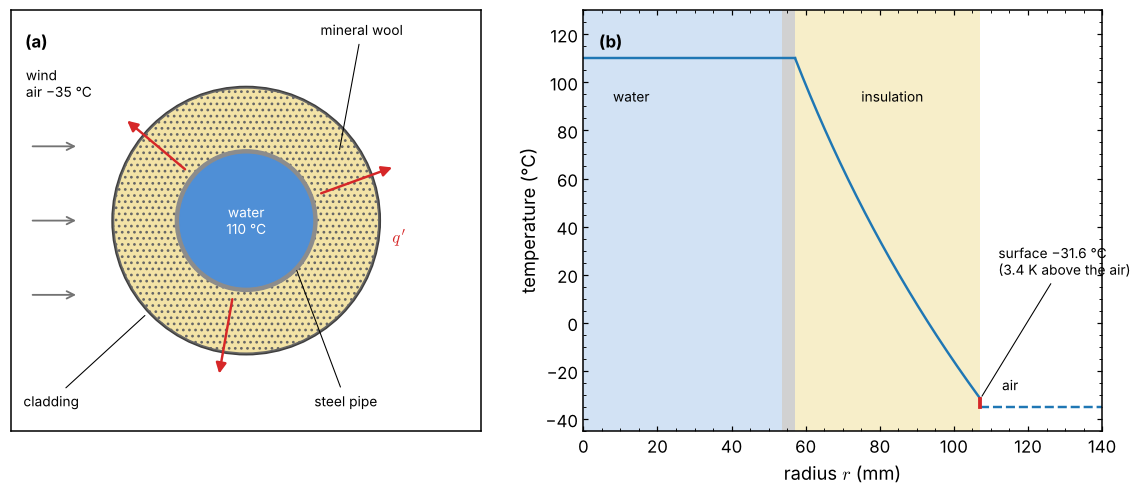

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.4))

# (a) the cross-section
mm = 1e3
ax1.add_patch(Circle((0, 0), r_2 * mm + 1.2, color="0.25"))                     # cladding
ax1.add_patch(Circle((0, 0), r_2 * mm, facecolor="#f3e3a6", edgecolor="0.4", hatch="..."))
ax1.add_patch(Circle((0, 0), r_1 * mm, color="0.55"))                           # steel
ax1.add_patch(Circle((0, 0), r_i * mm, color="#4f8fd6"))                        # water
for angle in np.radians([20, 140, 260]):
    c, s = math.cos(angle), math.sin(angle)
    ax1.add_patch(FancyArrowPatch((62 * c, 62 * s), (128 * c, 128 * s), arrowstyle="-|>",
                                  mutation_scale=14, color="C3", lw=1.6))
for y in (-60, 0, 60):
    ax1.add_patch(FancyArrowPatch((-175, y), (-135, y), arrowstyle="->", mutation_scale=12,
                                  color="0.45", lw=1.2))
ax1.text(0, 0, "water\n110 °C", ha="center", va="center", color="white", fontsize=9)
ax1.annotate("steel pipe", (40, -38), (55, -150), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.7))
ax1.annotate("mineral wool", (75, 55), (60, 150), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.7))
ax1.annotate("cladding", (-80, -75), (-180, -150), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.7))
ax1.text(-178, 100, "wind\nair −35 °C", fontsize=9)
ax1.text(118, -18, r"$q'$", color="C3")
ax1.set_xlim(-190, 190)
ax1.set_ylim(-170, 170)
ax1.set_aspect("equal")
ax1.set_xticks([])
ax1.set_yticks([])
panel_label(ax1, "(a)")

# (b) the temperature from the axis outwards
r_in = np.linspace(r_1, r_2, 200)
T_in = T_w - (T_w - T_s) * np.log(r_in / r_1) / np.log(r_2 / r_1)
ax2.axvspan(0, r_i * mm, color="#4f8fd6", alpha=0.25, lw=0)
ax2.axvspan(r_i * mm, r_1 * mm, color="0.55", alpha=0.4, lw=0)
ax2.axvspan(r_1 * mm, r_2 * mm, color="#f3e3a6", alpha=0.6, lw=0)
ax2.plot([0, r_1 * mm], [T_w - 273.15] * 2, "C0")
ax2.plot(r_in * mm, T_in - 273.15, "C0", label="Eq. (1.5)")
ax2.plot([r_2 * mm, 140], [T_inf - 273.15] * 2, "C0", ls="--")
ax2.plot([r_2 * mm, r_2 * mm], [T_s - 273.15, T_inf - 273.15], "C3", lw=2.5)
ax2.annotate(f"surface {T_s - 273.15:.1f} °C\n(3.4 K above the air)".replace("-", "−"), (r_2 * mm, T_s - 273.15),
             (112, 20), fontsize=9, arrowprops=dict(arrowstyle="-", lw=0.7))
ax2.text(8, 92, "water", fontsize=9)
ax2.text(75, 92, "insulation", fontsize=9)
ax2.text(113, -28, "air", fontsize=9)
ax2.set_xlim(0, 140)
ax2.set_ylim(-45, 130)
ax2.set_xlabel(r"radius $r$ (mm)")
ax2.set_ylabel(r"temperature (°C)")
panel_label(ax2, "(b)")
plt.show()

**Figure 1.1.** (a) Cross-section of the insulated district-heating pipe, drawn to scale.
Heat flows outwards through the insulation and leaves the cladding by convection to the
wind and by radiation. (b) Temperature from the axis outwards. The water and the steel
are at 110 °C; the temperature falls logarithmically through the insulation, Eq. (1.5);
the step at the cladding (red) is the 3.4 K that drives convection and radiation into
the air at −35 °C.

## 1.4 Linearising radiation: resistances in a network

Equation (1.6) can be written as a chain of resistances if radiation is written like
convection. Factorising the difference of fourth powers exactly,

$$
\varepsilon\sigma\,(T_s^4 - T_{\rm sur}^4) = h_r\,(T_s - T_{\rm sur}), \qquad
h_r = \varepsilon\sigma\,(T_s + T_{\rm sur})(T_s^2 + T_{\rm sur}^2).
\tag{1.8}
$$

When $T_{\rm sur} = T_\infty$, convection and radiation act in parallel between the same
two temperatures, with outer resistance $R'_{\rm out} = 1/[2\pi r_2 (h + h_r)]$, in series
with the insulation:

$$
q' = \frac{T_w - T_\infty}{R'_{\rm ins} + R'_{\rm out}}.
\tag{1.9}
$$

The catch is that $h_r$ depends on $T_s$, which is not yet known. The classical way
round it is *successive substitution*: guess $T_s$, compute $h_r$ and then $T_s$ from
Eq. (1.9), and repeat. For the pipe, $h_r = 2.8$ W/(m² K), the outer resistance is
0.053 m K/W and the insulation 2.223 m K/W. The insulation takes 97.7 % of the total, so
any error in the outer resistance barely changes $T_s$, and successive substitution
converges in a few steps (Section 1.6). It converges slowly, or not at all, when the
outer resistance dominates, as for a bare pipe; Newton's method does not have this
weakness.

In [5]:
h_r = eps * SIGMA_SB * (T_s + T_sur) * (T_s**2 + T_sur**2)
R_out = 1 / (2 * math.pi * r_2 * (h + h_r))
print(f"h_r = {h_r:.3f} W/(m2 K),  R'_out = {R_out:.4f} m K/W,  "
      f"insulation share of the total resistance = {100 * R_ins / (R_ins + R_out):.1f} %")
print(f"Eq. (1.9): q' = {(T_w - T_inf) / (R_ins + R_out):.4f} W/m  (Newton: {q:.4f} W/m)")

h_r = 2.817 W/(m2 K),  R'_out = 0.0534 m K/W,  insulation share of the total resistance = 97.7 %
Eq. (1.9): q' = 63.6960 W/m  (Newton: 63.6960 W/m)


## 1.5 When the circulation stops

Suppose the pumps stop. The water no longer brings heat, and the pipe cools by the same
losses. Inside the pipe, slow natural convection keeps the water nearly at one
temperature, and the steel follows it. The heat stored per metre and per kelvin is

$$
C' = (\rho c)_w\,\pi r_i^2 + (\rho c)_{\rm steel}\,\pi (r_1^2 - r_i^2),
$$

about 42 kJ/(m K), nine-tenths of it in the water. The insulation itself stores
little heat, and the profile through it adjusts in a time of order
$(r_2 - r_1)^2/\alpha_{\rm ins} \approx 1.3$ h, much shorter than the cooling, as the
numbers below show. So at each moment the loss is the steady loss, Eq. (1.9), at the
current water temperature. The energy balance (1.4) of the pipe and its water is then

$$
C'\,\frac{dT_w}{dt} = -\frac{T_w - T_\infty}{R'_{\rm tot}}, \qquad R'_{\rm tot} = R'_{\rm ins} + R'_{\rm out},
\tag{1.10}
$$

a *lumped* model, since the water is described by one temperature. With $C'$ and
$R'_{\rm tot}$ constant, the solution is an exponential approach to the air temperature
with the time constant $\tau = C'R'_{\rm tot}$, and the water reaches $0\,^\circ\mathrm{C}$
($T_f = 273.15$ K) at

$$
T_w(t) = T_\infty + (T_{w,0} - T_\infty)\,e^{-t/\tau}, \qquad
t_f = \tau\,\ln\frac{T_{w,0} - T_\infty}{T_f - T_\infty}.
\tag{1.11}
$$

In [6]:
A_w, A_steel = math.pi * r_i**2, math.pi * (r_1**2 - r_i**2)
rho_c_steel = 7850.0 * 460.0                     # carbon steel


def heat_capacity(T):
    """Heat capacity per metre and kelvin of the water and the steel, J/(m K)."""
    w = properties.water_properties(np.clip(T, 273.16, 473.15))
    return w["rho"] * w["cp"] * A_w + rho_c_steel * A_steel


C = heat_capacity(273.15 + 55.0)                 # at the mean of 110 C and 0 C
R_tot = R_ins + R_out
tau = C * R_tot
T_f = 273.15
t_f = tau * math.log((T_w - T_inf) / (T_f - T_inf))
rho_c_ins = 100.0 * 840.0                        # mineral wool: 100 kg/m3, 840 J/(kg K)
print(f"C' = {C / 1e3:.2f} kJ/(m K) ({100 * (C - rho_c_steel * A_steel) / C:.0f} % water)")
print(f"tau = C' R'_tot = {tau / 3600:.2f} h;  insulation time (r2 - r1)^2 rho c / k = "
      f"{t_ins**2 * rho_c_ins / k_ins / 3600:.2f} h")
print(f"Eq. (1.11): the water reaches 0 C after t_f = {t_f / 3600:.1f} h")

C' = 41.65 kJ/(m K) (89 % water)
tau = C' R'_tot = 26.34 h;  insulation time (r2 - r1)^2 rho c / k = 1.30 h
Eq. (1.11): the water reaches 0 C after t_f = 37.4 h


The water takes about a day and a half to reach $0\,^\circ\mathrm{C}$: $\tau = 26.3$ h and
$t_f = 37.4$ h. This is the time the operators have to restore circulation or drain the
pipe. Figure 1.2 shows how both answers depend on the insulation. The heat loss falls
steeply with the first centimetres of insulation and slowly after that, because the
resistance grows only as the logarithm of the outer radius. The cladding emissivity
matters for a bare pipe and hardly at all for an insulated one. The time to reach
$0\,^\circ\mathrm{C}$ grows with the resistance, from 22 hours for 25 mm of insulation to
59 hours for 100 mm.

insulation    25 mm: q' =  107.2 W/m,  water reaches 0 C after  22.2 h
insulation    50 mm: q' =   63.7 W/m,  water reaches 0 C after  37.4 h
insulation   100 mm: q' =   40.1 W/m,  water reaches 0 C after  59.4 h


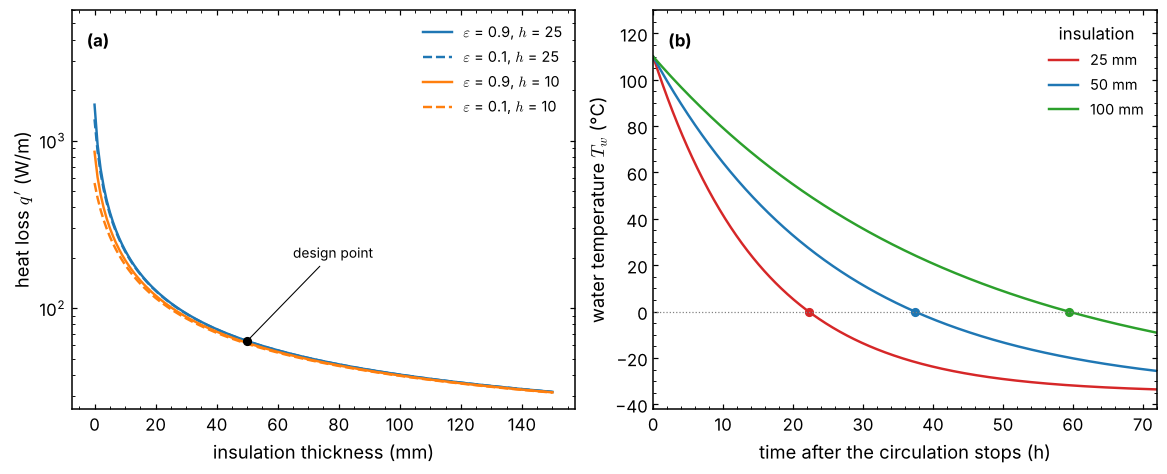

In [7]:
def loss_per_metre(t, eps=eps, h=h, T_w=T_w):
    """Steady heat loss per metre for insulation thickness t (t = 0: bare pipe)."""
    if t == 0:
        P = 2 * math.pi * r_1
        return P * (h * (T_w - T_inf) + eps * SIGMA_SB * (T_w**4 - T_sur**4))
    f, df = surface_balance(t, eps=eps, h=h, T_w=T_w)
    Ts, _ = numerics.newton(f, df, x0=T_w)
    return (T_w - Ts) / resistance_ins(t)


def lumped_cooling(t_ins_value, t):
    """Eq. (1.11) for insulation thickness t_ins_value: returns T_w(t) and t_f."""
    f, df = surface_balance(t_ins_value)
    Ts, _ = numerics.newton(f, df, x0=T_w)
    rr = r_1 + t_ins_value
    hr = eps * SIGMA_SB * (Ts + T_sur) * (Ts**2 + T_sur**2)
    tau_ = C * (resistance_ins(t_ins_value) + 1 / (2 * math.pi * rr * (h + hr)))
    return T_inf + (T_w - T_inf) * np.exp(-t / tau_), tau_ * math.log((T_w - T_inf) / (T_f - T_inf))


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
thick = np.linspace(0, 0.15, 151)
for e, hh, style in ((0.9, 25.0, "C0-"), (0.1, 25.0, "C0--"), (0.9, 10.0, "C1-"), (0.1, 10.0, "C1--")):
    ax1.semilogy(thick * 1e3, [loss_per_metre(t, eps=e, h=hh) for t in thick], style,
                 label=rf"$\varepsilon$ = {e}, $h$ = {hh:.0f}")
ax1.plot(t_ins * 1e3, q, "ko", ms=5)
ax1.annotate("design point", (t_ins * 1e3, q), (65, 200), fontsize=9,
             arrowprops=dict(arrowstyle="-", lw=0.7))
ax1.set_ylim(25, 6000)
ax1.set_xlabel("insulation thickness (mm)")
ax1.set_ylabel(r"heat loss $q'$ (W/m)")
ax1.legend(loc="upper right")
panel_label(ax1, "(a)")

t = np.linspace(0, 72 * 3600, 721)
for t_value, color in ((0.025, "C3"), (0.050, "C0"), (0.100, "C2")):
    Tw_t, tf_value = lumped_cooling(t_value, t)
    ax2.plot(t / 3600, Tw_t - 273.15, color=color, label=f"{t_value * 1e3:.0f} mm")
    ax2.plot(tf_value / 3600, 0, "o", color=color, ms=5)
    print(f"insulation {t_value * 1e3:5.0f} mm: q' = {loss_per_metre(t_value):6.1f} W/m,"
          f"  water reaches 0 C after {tf_value / 3600:5.1f} h")
ax2.axhline(0, color="0.5", lw=0.8, ls=":")
ax2.set_xlabel(r"time after the circulation stops (h)")
ax2.set_ylabel(r"water temperature $T_w$ (°C)")
ax2.set_xlim(0, 72)
ax2.set_ylim(-42, 130)
ax2.legend(title="insulation", loc="upper right")
panel_label(ax2, "(b)")
plt.show()

**Figure 1.2.** (a) Heat loss per metre against the thickness of insulation, for a
painted ($\varepsilon = 0.9$) and a bright ($\varepsilon = 0.1$) cladding, in a wind
($h = 25$ W/(m² K)) and in nearly still air ($h = 10$). Thickness zero is the bare pipe.
(b) Temperature of the water after the circulation stops, Eq. (1.11), for three
thicknesses of insulation; the dots mark the times at which it reaches 0 °C.

## 1.6 Checks

Four things in this chapter can be checked against an independent calculation.

*The root finders.* Newton's method, successive substitution and bisection all solve
Eq. (1.6). Figure 1.3a shows how fast each reaches the root. Bisection gains one binary
digit per step and needs 37 steps to reach $10^{-10}$ K. Successive substitution gains
almost three decimal digits per step here, because the outer resistance is small, and
is as quick as Newton's method. Newton's method doubles the number of correct digits at
each step (an error of 19 K, then 0.24 K, $4\times10^{-5}$ K and $8\times10^{-13}$ K), from
an initial guess at the water temperature.

*The steady profile.* A finite-volume solution of the conduction equation through the
insulation, with the nonlinear surface balance as its boundary condition
(`reference.insulated_pipe_fv`), is independent of Eqs. (1.5) and (1.6). Its heat loss
converges to the Newton result with an error that falls as the square of the cell size
(Figure 1.3b), as a second-order method should.

*The cooling.* The lumped model (1.10) makes three simplifications: it takes $C'$ and
$h_r$ constant, it neglects the heat stored in the insulation and the cladding, and it
assumes the insulation profile is always steady. Two more complete calculations remove
them. The first integrates Eq. (1.10) numerically with $C'(T_w)$ from the water
properties and the exact radiation, solving Eq. (1.6) at every step. The second is the
finite-volume model in time, with 60 cells in the insulation, a cladding 0.5 mm thick,
and the heat stored in both. Its energy balance (heat lost against the fall in stored
heat) closes to better than one part in a million.

*The properties.* The water and air properties of `engtransport.properties` are short
formulas fitted to the international reference equations (IAPWS-95 for water, Lemmon and
co-workers for air) by `scripts/fit_properties.py`, which records the largest error of
each fit; all are below 0.25 %.

In [8]:
# (a) convergence of the three root finders
T_bis, hist_bis = numerics.bisect(f, T_inf, T_w, xtol=1e-12)
hist_sub, T = [T_w], T_w
for _ in range(8):
    hr = eps * SIGMA_SB * (T + T_sur) * (T**2 + T_sur**2)
    Ro = 1 / (2 * math.pi * r_2 * (h + hr))
    T = T_inf + (T_w - T_inf) * Ro / (R_ins + Ro)
    hist_sub.append(T)
err = {name: np.abs(np.array(hh) - T_s) for name, hh in
       (("bisection", hist_bis), ("successive substitution", hist_sub), ("Newton", history))}
for name, e in err.items():
    first = np.argmax(e < 1e-10) if np.any(e < 1e-10) else None
    print(f"{name:24s}: error below 1e-10 K after {first} steps")

# (b) finite volumes against Eq. (1.6)
cells = np.array([5, 10, 20, 40, 80, 160, 320])
q_fv = np.array([reference.insulated_pipe_fv(T_w, r_1, r_2, k_ins, h, eps, T_inf, n_cells=n)["q"]
                 for n in cells])
fv_error = np.abs(q_fv - q)
order = np.polyfit(np.log(cells[2:]), np.log(fv_error[2:]), 1)[0]
print(f"finite volumes: q' error {fv_error[0]:.1e} W/m with {cells[0]} cells, "
      f"{fv_error[-1]:.1e} W/m with {cells[-1]} cells; observed order {-order:.2f}")

# (c) cooling: closed form, lumped with variable properties and exact radiation, finite volumes
t = np.linspace(0, 60 * 3600, 1201)
T_closed = T_inf + (T_w - T_inf) * np.exp(-t / tau)


def loss_at(Tw_value):
    fw, dfw = surface_balance(T_w=Tw_value)
    Ts_value, _ = numerics.newton(fw, dfw, x0=Tw_value)
    return (Tw_value - Ts_value) / R_ins


sol = solve_ivp(lambda tt, y: [-loss_at(y[0]) / heat_capacity(y[0])], (0, t[-1]), [T_w],
                t_eval=t, rtol=1e-10, atol=1e-10)
T_lumped = sol.y[0]
C_clad = 2 * math.pi * r_2 * 0.0005 * rho_c_steel
fv = reference.insulated_pipe_fv(T_w, r_1, r_2, k_ins, h, eps, T_inf, n_cells=60, t_eval=t,
                                 rho_c_ins=rho_c_ins, C_cladding=C_clad, C_pipe=heat_capacity)
T_fv = fv["T_water"]


def freeze_time(T_curve):
    return np.interp(T_f, T_curve[::-1], t[::-1])


for name, curve in (("closed form, Eq. (1.11)", T_closed), ("lumped, exact radiation", T_lumped),
                    ("finite volumes", T_fv)):
    print(f"{name:24s}: t_f = {freeze_time(curve) / 3600:6.2f} h")
print(f"largest difference from the finite volumes: closed form {np.max(np.abs(T_closed - T_fv)):.2f} K,"
      f" lumped {np.max(np.abs(T_lumped - T_fv)):.2f} K")
print(f"finite-volume energy balance closes to {fv['energy_error']:.1e}")
print("largest fit errors of the property formulas:",
      {k: f"{v:.1e}" for k, v in et._property_fits.MAX_RELATIVE_ERROR.items() if k.startswith(("air", "water"))})

bisection               : error below 1e-10 K after 37 steps
successive substitution : error below 1e-10 K after 5 steps
Newton                  : error below 1e-10 K after 4 steps
finite volumes: q' error 7.3e-02 W/m with 5 cells, 2.2e-05 W/m with 320 cells; observed order 1.98
closed form, Eq. (1.11) : t_f =  37.44 h
lumped, exact radiation : t_f =  37.60 h
finite volumes          : t_f =  38.07 h
largest difference from the finite volumes: closed form 0.86 K, lumped 0.66 K
finite-volume energy balance closes to 3.2e-07
largest fit errors of the property formulas: {'air cp': '8.8e-04', 'air mu': '4.8e-04', 'air k': '1.1e-03', 'water cp': '1.9e-03', 'water rho': '3.3e-04', 'water k': '2.2e-03', 'water mu': '3.3e-04'}


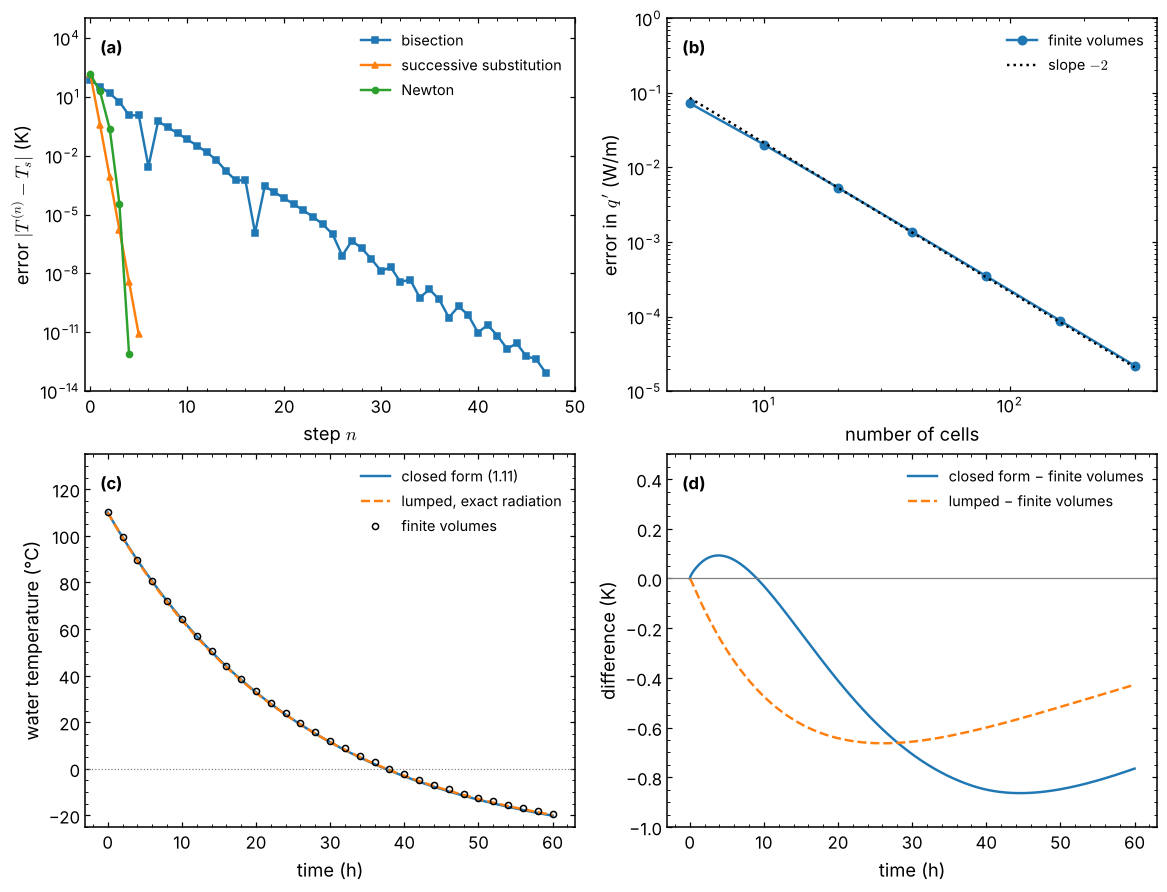

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.0))
ax = axes[0, 0]
for (name, e), mk in zip(err.items(), ("s", "^", "o")):
    k_steps = np.arange(len(e))
    keep = e > 0
    ax.semilogy(k_steps[keep], e[keep], mk + "-", ms=4, label=name)
ax.set_xlim(-0.5, 50)
ax.set_ylim(1e-14, 1e5)
ax.set_xlabel(r"step $n$")
ax.set_ylabel(r"error $|T^{(n)} - T_s|$ (K)")
ax.legend(loc="upper right")
panel_label(ax, "(a)")

ax = axes[0, 1]
ax.loglog(cells, fv_error, "o-", label="finite volumes")
ax.loglog(cells, fv_error[2] * (cells[2] / cells) ** 2, "k:", label=r"slope $-2$")
ax.set_ylim(1e-5, 1.0)
ax.set_xlabel("number of cells")
ax.set_ylabel(r"error in $q'$ (W/m)")
ax.legend(loc="upper right")
panel_label(ax, "(b)")

ax = axes[1, 0]
ax.plot(t / 3600, T_closed - 273.15, "C0-", label="closed form (1.11)")
ax.plot(t / 3600, T_lumped - 273.15, "C1--", label="lumped, exact radiation")
ax.plot(t[::40] / 3600, T_fv[::40] - 273.15, "ko", ms=4, mfc="none", label="finite volumes")
ax.axhline(0, color="0.5", lw=0.8, ls=":")
ax.set_ylim(-25, 135)
ax.set_xlabel("time (h)")
ax.set_ylabel(r"water temperature (°C)")
ax.legend(loc="upper right")
panel_label(ax, "(c)")

ax = axes[1, 1]
ax.plot(t / 3600, T_closed - T_fv, "C0-", label="closed form − finite volumes")
ax.plot(t / 3600, T_lumped - T_fv, "C1--", label="lumped − finite volumes")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylim(-1.0, 0.5)
ax.set_xlabel("time (h)")
ax.set_ylabel("difference (K)")
ax.legend(loc="upper right")
panel_label(ax, "(d)")
plt.show()

**Figure 1.3.** Checks. (a) Error of the three root finders for the surface temperature,
Eq. (1.6). (b) Error of the finite-volume heat loss against the number of cells; the
dotted line has slope −2. (c) The water cooling after the circulation stops: the closed
form (1.11), the lumped model with variable properties and exact radiation, and the
finite-volume model with the heat stored in the insulation and the cladding. (d)
Differences between them.

The three cooling curves agree to better than 1 K over two and a half days, and the
times to reach $0\,^\circ\mathrm{C}$ to within 2 %. The difference that remains comes
mostly from the heat stored in the insulation, which the finite-volume model releases
and the lumped models ignore; it makes the real pipe cool slightly more slowly. Taking
$C'$ and $h_r$ constant costs almost nothing. For this pipe the closed form (1.11) is
good enough, and the reason is now quantified rather than assumed.

## 1.7 What to trust

* *The heat-transfer coefficient.* Here $h$ was given. Because the insulation carries
  97.7 % of the resistance, an error of ±30 % in $h$ changes the heat loss by less than
  1 % (computed below). For a bare pipe the same error would change it by about 24 %.
  Whether a result is sensitive to $h$ is the first question to ask.
* *The insulation.* Its conductivity sets the answer almost alone: ±10 % in $k$ gives
  about ±10 % in $q'$. Wet mineral wool conducts many times better than dry (Exercise 2),
  so keeping the cladding watertight matters more than anything on the outside.
* *The surroundings.* A clear night sky is much colder than the air, and radiation to it
  increases the loss slightly (Exercise 1).
* *The water.* Still water in a cold pipe does not stay perfectly mixed: the coldest
  water collects at the bottom, and supports, valves and other thermal bridges cool
  faster than a straight pipe. Freezing starts at such places before the mean
  temperature reaches 0 °C, so $t_f$ is an upper bound for a real line. Reaching 0 °C is
  also only the start: the latent heat of the ice delays complete freezing much longer
  (Exercise 4).

In [10]:
for factor in (0.7, 1.3):
    print(f"h x {factor}: q' changes by {100 * (loss_per_metre(t_ins, h=h * factor) / q - 1):+.2f} %;"
          f"  bare pipe: {100 * (loss_per_metre(0, h=h * factor) / loss_per_metre(0) - 1):+.1f} %")
k_saved = k_ins
for factor in (0.9, 1.1):
    k_ins = k_saved * factor
    print(f"k_ins x {factor}: q' changes by {100 * (loss_per_metre(t_ins) / q - 1):+.1f} %")
k_ins = k_saved

h x 0.7: q' changes by -0.86 %;  bare pipe: -23.8 %
h x 1.3: q' changes by +0.50 %;  bare pipe: +23.8 %
k_ins x 0.9: q' changes by -9.8 %
k_ins x 1.1: q' changes by +9.7 %


## Summary

* Heat moves by conduction (Fourier's law, Eq. 1.1), by convection (Newton's law of
  cooling, Eq. 1.2, which defines $h$) and by radiation (Eq. 1.3, nonlinear in
  temperature).
* An energy balance on a control volume, Eq. (1.4), turns these laws into equations.
  At a surface, which stores nothing, it is the balance between conduction in and
  convection and radiation out, Eq. (1.6).
* Steady conduction through a cylindrical layer has the resistance
  $R' = \ln(r_2/r_1)/2\pi k$ per metre; resistances in series add.
* A nonlinear balance is solved by Newton's method, whose error is squared at each
  step. Radiation written as $h_r(T_s - T_{\rm sur})$ gives a resistance network
  instead, solved by successive substitution.
* A body that stays at one temperature cools exponentially with the time constant
  $\tau = C'R'$, Eq. (1.11). For the pipe, $\tau = 26$ h, and the water reaches 0 °C
  about 37 hours after the circulation stops.

## Exercises

Sample solutions are in [`solutions/part1_conduction/01_solutions.ipynb`](../../solutions/part1_conduction/01_solutions.ipynb).

1. **A clear night.** On a clear night the sky radiates like a black body at a
   temperature well below that of the air; take $T_{\rm sur} = T_\infty - 20$ K. Rewrite
   Eq. (1.6) with separate $T_\infty$ and $T_{\rm sur}$ and find $T_s$ and $q'$ for the
   painted cladding ($\varepsilon = 0.9$) and for bright aluminium ($\varepsilon = 0.1$).
   Can the cladding become colder than the air? Why does this matter for frost on
   car roofs?
2. **The resistances that were neglected.** With the pumps running, the coefficient
   between the water and the steel is about 2000 W/(m² K), and the steel conducts with
   $k = 50$ W/(m K). Compute both resistances per metre and compare them with
   $R'_{\rm ins}$. Then suppose the insulation is soaked by rain and its conductivity
   rises to 0.4 W/(m K). Find the new heat loss and the new time to reach 0 °C.
3. **Designing for an outage.** The network operator wants the water to stay above
   0 °C for at least 48 hours after the circulation stops at −35 °C. Using Eq. (1.11),
   find the thinnest insulation that achieves this by bisection on the thickness, and
   compare it with the standard thicknesses of 60, 80 and 100 mm. How much heat does
   the extra insulation save per kilometre and per day in normal operation?
4. **Freezing.** Once the water reaches 0 °C it starts to freeze, and it stays at
   0 °C while it gives up its latent heat, $L = 334$ kJ/kg. Estimate how long it takes
   to freeze a quarter of the water in the pipe of this chapter, and compare it with
   the 37 hours needed to cool it to 0 °C. (The ice forms on the wall and adds a layer
   of $k \approx 2.2$ W/(m K); show that this layer can be neglected.)

## Suggested references

* T. L. Bergman, A. S. Lavine, F. P. Incropera and D. P. DeWitt, *Fundamentals of Heat
  and Mass Transfer*, 8th ed. (Wiley, 2017).
* J. H. Lienhard IV and J. H. Lienhard V, *A Heat Transfer Textbook*, 5th ed. (Dover,
  2019); free from the authors at [ahtt.mit.edu](https://ahtt.mit.edu).
* I. Newton (published anonymously), "Scala graduum caloris", *Phil. Trans. R. Soc.*
  **22**, 824 (1701).
* J. Stefan, "Über die Beziehung zwischen der Wärmestrahlung und der Temperatur",
  *Sitzungsber. Akad. Wiss. Wien, Math.-Naturwiss. Cl., Abt. II* **79**, 391 (1879).
* L. Boltzmann, "Ableitung des Stefan'schen Gesetzes, betreffend die Abhängigkeit der
  Wärmestrahlung von der Temperatur aus der electromagnetischen Lichttheorie",
  *Ann. Phys.* **258**, 291 (1884).
* W. Wagner and A. Pruß, "The IAPWS formulation 1995 for the thermodynamic properties
  of ordinary water substance for general and scientific use", *J. Phys. Chem. Ref.
  Data* **31**, 387 (2002).
* E. W. Lemmon and R. T. Jacobsen, "Viscosity and thermal conductivity equations for
  nitrogen, oxygen, argon, and air", *Int. J. Thermophys.* **25**, 21 (2004).
* I. H. Bell, J. Wronski, S. Quoilin and V. Lemort, "Pure and pseudo-pure fluid
  thermophysical property evaluation and the open-source thermophysical property
  library CoolProp", *Ind. Eng. Chem. Res.* **53**, 2498 (2014).

---

**Next:** [2. Steady conduction and thermal resistance](02_steady_conduction.ipynb)